In [13]:
import os
import sys
import warnings
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000)

sns.set_theme(style="whitegrid", palette="muted")
warnings.filterwarnings('ignore')

In [14]:
df_raw = pd.read_csv('Online Retail.csv', encoding='ISO-8859-1')

print(f"Dimensi Dataset Awal: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom\n")
df_raw.info()
df_raw.head()

Dimensi Dataset Awal: 541909 baris, 8 kolom

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [15]:
df_clean = df_raw.dropna(subset=['Description', 'CustomerID']).copy()
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
df_clean = df_clean[df_clean['Quantity'] > 0]
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

stats_summary = pd.DataFrame({
    'Indikator Statistik': ['Jumlah Baris Transaksi', 'Jumlah Invoice Unik', 'Jumlah Pelanggan Unik'],
    'Sebelum Pembersihan': [len(df_raw), df_raw['InvoiceNo'].nunique(), df_raw['CustomerID'].nunique(dropna=True)],
    'Sesudah Pembersihan': [len(df_clean), df_clean['InvoiceNo'].nunique(), df_clean['CustomerID'].nunique()],
    'Selisih Terbuang': [len(df_raw) - len(df_clean), df_raw['InvoiceNo'].nunique() - df_clean['InvoiceNo'].nunique(), df_raw['CustomerID'].nunique(dropna=True) - df_clean['CustomerID'].nunique()]
})

stats_summary

,Indikator Statistik,Sebelum Pembersihan,Sesudah Pembersihan,Selisih Terbuang
0,Jumlah Baris Transaksi,541909,397924,143985
1,Jumlah Invoice Unik,25900,18536,7364
2,Jumlah Pelanggan Unik,4372,4339,33


In [16]:
df_sorted = df_clean.sort_values(by=['CustomerID', 'InvoiceDate'])

invoice_itemsets = df_sorted.groupby(['CustomerID', 'InvoiceDate', 'InvoiceNo'])['Description'] \
                            .apply(lambda x: sorted(list(set(x)))) \
                            .reset_index()

customer_sequences_df = invoice_itemsets.groupby('CustomerID')['Description'].apply(list).reset_index()
customer_sequences_df.columns = ['CustomerID', 'Sequence']

sequences = customer_sequences_df['Sequence'].tolist()
customer_sequences_df.head()

CustomerID  \
0       12346   
1       12347   
2       12348   
3       12349   
4       12350   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                            

In [17]:
def mine_sequential_patterns(sequences, min_support_ratio=0.015):
    N = len(sequences)
    min_count = int(min_support_ratio * N)
    
    item_cust_count = Counter()
    for seq in sequences:
        unique_items = set(item for itemset in seq for item in itemset)
        for item in unique_items:
            item_cust_count[item] += 1
            
    seq_pair_count = Counter()
    for seq in sequences:
        n_trans = len(seq)
        if n_trans >= 2:
            cust_pairs = set()
            for t1 in range(n_trans):
                for t2 in range(t1 + 1, n_trans):
                    for item1 in seq[t1]:
                        for item2 in seq[t2]:
                            cust_pairs.add((item1, item2))
            for pair in cust_pairs:
                seq_pair_count[pair] += 1
                
    results = []
    for (item_a, item_b), count in seq_pair_count.items():
        if count >= min_count:
            supp = count / N
            conf = count / item_cust_count[item_a]
            results.append({
                'Pola Berurutan': f"<{item_a}> -> <{item_b}>",
                'Item A': item_a,
                'Item B': item_b,
                'Support Count': count,
                'Support (%)': round(supp * 100, 2),
                'Confidence (%)': round(conf * 100, 2)
            })
            
    df_res = pd.DataFrame(results)
    if not df_res.empty:
        df_res = df_res.sort_values(by=['Support (%)', 'Confidence (%)'], ascending=False).reset_index(drop=True)
    return df_res

df_patterns = mine_sequential_patterns(sequences, min_support_ratio=0.015)
df_patterns.head(10)

,Pola Berurutan,Item A,Item B,Support Count,Support (%),Confidence (%)
0,<WHITE HANGING HEART T-LIGHT HOLDER> -> <WHITE HANGING HEART T-LIGHT HOLDER>,WHITE HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER,405,9.33,47.31
1,<REGENCY CAKESTAND 3 TIER> -> <REGENCY CAKESTAND 3 TIER>,REGENCY CAKESTAND 3 TIER,REGENCY CAKESTAND 3 TIER,330,7.61,37.46
2,<JUMBO BAG RED RETROSPOT> -> <JUMBO BAG RED RETROSPOT>,JUMBO BAG RED RETROSPOT,JUMBO BAG RED RETROSPOT,312,7.19,49.13
3,<ASSORTED COLOUR BIRD ORNAMENT> -> <ASSORTED COLOUR BIRD ORNAMENT>,ASSORTED COLOUR BIRD ORNAMENT,ASSORTED COLOUR BIRD ORNAMENT,291,6.71,42.92
4,<PARTY BUNTING> -> <PARTY BUNTING>,PARTY BUNTING,PARTY BUNTING,280,6.45,39.55
5,<LUNCH BAG RED RETROSPOT> -> <LUNCH BAG RED RETROSPOT>,LUNCH BAG RED RETROSPOT,LUNCH BAG RED RETROSPOT,276,6.36,51.88
6,<LUNCH BAG BLACK SKULL.> -> <LUNCH BAG BLACK SKULL.>,LUNCH BAG BLACK SKULL.,LUNCH BAG BLACK SKULL.,229,5.28,50.00
7,<SET OF 3 CAKE TINS PANTRY DESIGN > -> <SET OF 3 CAKE TINS PANTRY DESIGN >,SET OF 3 CAKE TINS PANTRY DESIGN,SET OF 3 CAKE TINS PANTRY DESIGN,225,5.19,35.16
8,<LUNCH BAG RED RETROSPOT> -> <LUNCH BAG BLACK SKULL.>,LUNCH BAG RED RETROSPOT,LUNCH BAG BLACK SKULL.,212,4.89,39.85
9,<LUNCH BAG CARS BLUE> -> <LUNCH BAG RED RETROSPOT>,LUNCH BAG CARS BLUE,LUNCH BAG RED RETROSPOT,209,4.82,43.63


In [ ]:
df_patterns = mine_sequential_patterns(sequences, min_support_ratio=0.015)
df_patterns.head(10)

In [ ]:
top3_patterns = df_patterns.head(3)
top3_patterns

,Pola Berurutan,Item A,Item B,Support Count,Support (%),Confidence (%)
0,<WHITE HANGING HEART T-LIGHT HOLDER> -> <WHITE HANGING HEART T-LIGHT HOLDER>,WHITE HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER,405,9.33,47.31
1,<REGENCY CAKESTAND 3 TIER> -> <REGENCY CAKESTAND 3 TIER>,REGENCY CAKESTAND 3 TIER,REGENCY CAKESTAND 3 TIER,330,7.61,37.46
2,<JUMBO BAG RED RETROSPOT> -> <JUMBO BAG RED RETROSPOT>,JUMBO BAG RED RETROSPOT,JUMBO BAG RED RETROSPOT,312,7.19,49.13


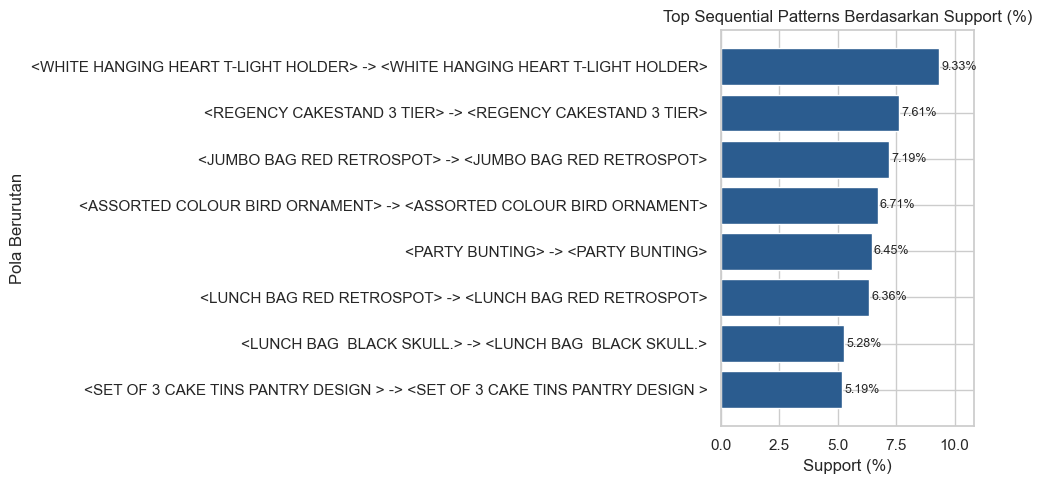

In [ ]:
plt.figure(figsize=(10, 5))
top_plot = df_patterns.head(8).sort_values(by='Support (%)', ascending=True)

bars = plt.barh(top_plot['Pola Berurutan'], top_plot['Support (%)'], color='#2b5c8f')
plt.title('Top Sequential Patterns Berdasarkan Support (%)')
plt.xlabel('Support (%)')
plt.ylabel('Pola Berurutan')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2, f'{width:.2f}%', va='center', ha='left', fontsize=9)

plt.xlim(0, max(top_plot['Support (%)']) + 1.5)
plt.tight_layout()
plt.show()